In [ ]:
!unzip "/content/drive/My Drive/split.zip" -d "/content/dataset"

Streaming output truncated to the last 5000 lines.
  inflating: /content/dataset/split/train/real/000000525013.jpg  
  inflating: /content/dataset/split/train/real/000000525043.jpg  
  inflating: /content/dataset/split/train/real/000000525122.jpg  
  inflating: /content/dataset/split/train/real/000000525156.jpg  
  inflating: /content/dataset/split/train/real/000000525159.jpg  
  inflating: /content/dataset/split/train/real/000000525257.jpg  
  inflating: /content/dataset/split/train/real/000000525279.jpg  
  inflating: /content/dataset/split/train/real/000000525291.jpg  
  inflating: /content/dataset/split/train/real/000000525330.jpg  
  inflating: /content/dataset/split/train/real/000000525343.jpg  
  inflating: /content/dataset/split/train/real/000000525366.jpg  
  inflating: /content/dataset/split/train/real/000000525403.jpg  
  inflating: /content/dataset/split/train/real/000000525410.jpg  
  inflating: /content/dataset/split/train/real/000000525454.jpg  
  inflating: /content/dat

In [ ]:
!unzip "/content/drive/My Drive/split2.zip" -d "/content/dataset"

Archive:  /content/drive/My Drive/split2.zip
  inflating: /content/dataset/split/test/real/-4kwwL-iZ2Q.jpg  
  inflating: /content/dataset/split/test/real/-djRG1vB1pw.jpg  
  inflating: /content/dataset/split/test/real/-lXcuISzufo.jpg  
  inflating: /content/dataset/split/test/real/-qwEUsg7UbI.jpg  
  inflating: /content/dataset/split/test/real/0aMMMUjiiEQ.jpg  
  inflating: /content/dataset/split/test/real/0Zx1bDv5BNY.jpg  
  inflating: /content/dataset/split/test/real/11GZVrMzfUU.jpg  
  inflating: /content/dataset/split/test/real/1qyw0De2XC8.jpg  
  inflating: /content/dataset/split/test/real/27ylvWv45Wc.jpg  
  inflating: /content/dataset/split/test/real/2k41e7OF8Rc.jpg  
  inflating: /content/dataset/split/test/real/2nX4pShh5JE.jpg  
  inflating: /content/dataset/split/test/real/2OalKAckLvU.jpg  
  inflating: /content/dataset/split/test/real/3kkQCmJpFlY.jpg  
  inflating: /content/dataset/split/test/real/3pffLvHFej8.jpg  
  inflating: /content/dataset/split/test/real/3RdHg46F-q0.j

In [ ]:
!pip install tensorflow seaborn matplotlib scikit-learn

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

In [ ]:
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))

Num GPUs Available: 1


In [ ]:
import tensorflow as tf

# Image settings
IMG_SIZE = 380
BATCH_SIZE = 32

# Dataset directories
train_dir = "/content/dataset/split/train"
val_dir = "/content/dataset/split/val"
test_dir = "/content/dataset/split/test"

# Rescaling for training, validation, and testing (no augmentation)
datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

# Data generators (no augmentation)
train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 29601 images belonging to 2 classes.
Found 3781 images belonging to 2 classes.
Found 3784 images belonging to 2 classes.


In [ ]:
from tensorflow.keras import layers, models, regularizers

# Define custom CNN with additional dense layer, dropout tuning, L2 regularization, and AUC metric
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.Conv2D(32, (5, 5), padding='same', activation='relu'),
    layers.Conv2D(32, (5, 5), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

# Compile model with Adam optimizer and AUC metric
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

In [ ]:
# Callbacks for early stopping and learning rate reduction
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_model.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1
)

# Train the model (up to 30 epochs, will stop early if overfitting starts)
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=30,
    callbacks=[early_stopping, reduce_lr, checkpoint]
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 476ms/step - accuracy: 0.6951 - auc: 0.7640 - loss: 0.7410
Epoch 1: val_loss improved from inf to 0.79634, saving model to best_model.keras
926/926 ━━━━━━━━━━━━━━━━━━━━ 546s 536ms/step - accuracy: 0.6951 - auc: 0.7641 - loss: 0.7409 - val_accuracy: 0.6996 - val_auc: 0.8108 - val_loss: 0.7963 - learning_rate: 1.0000e-04
Epoch 2/30
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 470ms/step - accuracy: 0.8410 - auc: 0.9171 - loss: 0.5131
Epoch 2: val_loss did not improve from 0.79634
926/926 ━━━━━━━━━━━━━━━━━━━━ 473s 511ms/step - accuracy: 0.8410 - auc: 0.9171 - loss: 0.5130 - val_accuracy: 0.7403 - val_auc: 0.8711 - val_loss: 0.8092 - learning_rate: 1.0000e-04
Epoch 3/30
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step - accuracy: 0.8807 - auc: 0.9467 - loss: 0.4231
Epoch 3: val_loss did not improve from 0.79634
926/926 ━━━━━━━━━━━━━━━━━━━━ 466s 503ms/step - accuracy: 0.8808 - auc: 0.9467 - loss: 0.4231 - val_accuracy: 0.7456 - val_auc: 0.8910 - val_loss: 0.9423 - le

In [ ]:
# Save the trained model in .keras format
model.save('optimized_final_model.keras')

# To verify if it's saved
print("Model saved as final_model.keras")

Model saved as final_model.keras


In [ ]:
# Load the model from the .keras file
loaded_model = tf.keras.models.load_model('optimized_final_model.keras')

# Verify if the model is loaded correctly
print("Model loaded successfully from final_model.keras")

Model loaded successfully from final_model.keras


119/119 ━━━━━━━━━━━━━━━━━━━━ 39s 326ms/step - accuracy: 0.9360 - auc: 0.5364 - loss: 0.2701
Test Accuracy: 0.9622, Test Loss: 0.2073
Test AUC: 0.9908
119/119 ━━━━━━━━━━━━━━━━━━━━ 36s 293ms/step


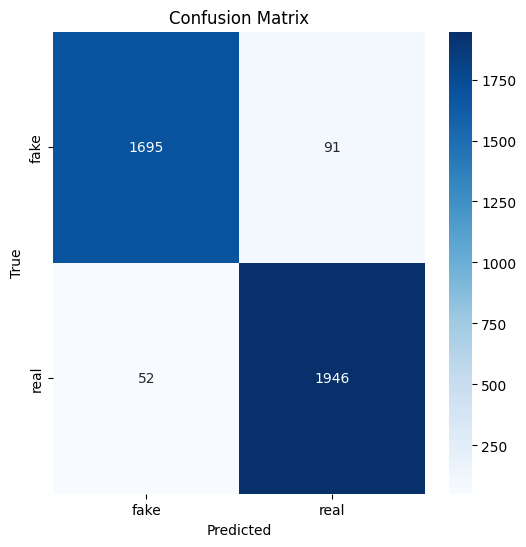

              precision    recall  f1-score   support

        fake       0.97      0.95      0.96      1786
        real       0.96      0.97      0.96      1998

    accuracy                           0.96      3784
   macro avg       0.96      0.96      0.96      3784
weighted avg       0.96      0.96      0.96      3784



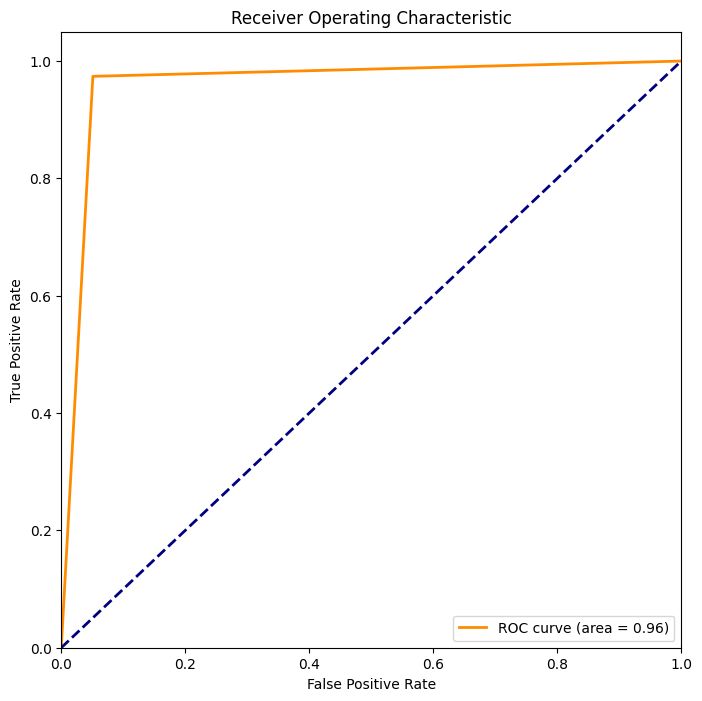

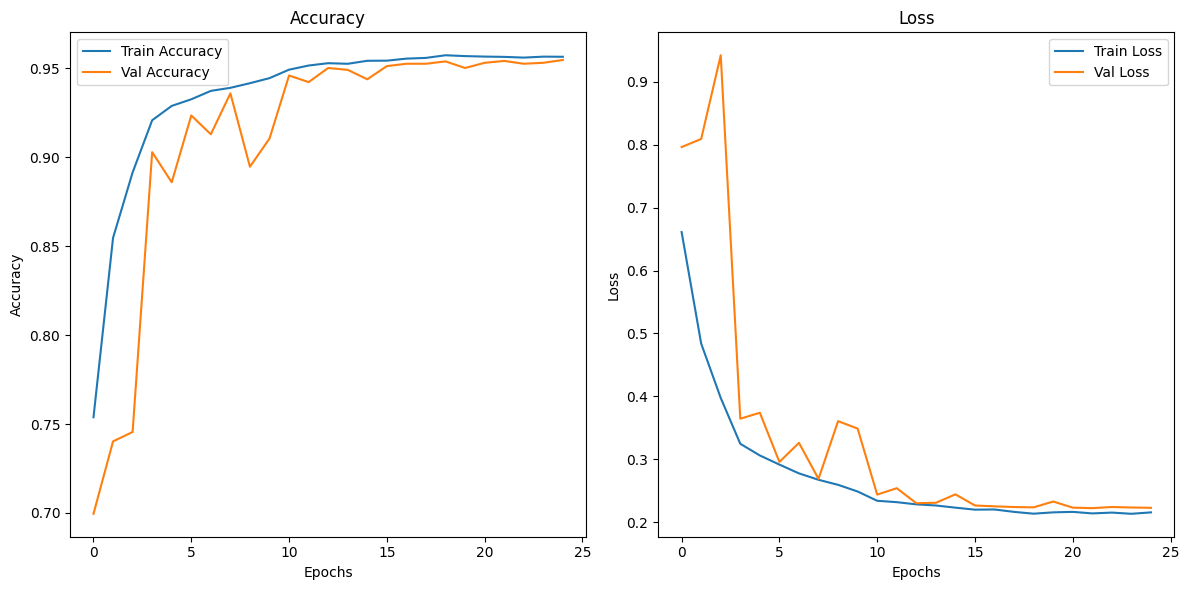

In [ ]:
# Load the best model (if using model checkpointing)
best_model = loaded_model

# Evaluate on the test set
results = best_model.evaluate(test_generator)
test_loss = results[0]
test_accuracy = results[1]
test_auc = results[2] if len(results) > 2 else None

print(f"Test Accuracy: {test_accuracy:.4f}, Test Loss: {test_loss:.4f}")
if test_auc is not None:
    print(f"Test AUC: {test_auc:.4f}")

# Get true labels and predictions for confusion matrix and ROC curve
test_labels = test_generator.classes
predictions = best_model.predict(test_generator, verbose=1)
predictions = (predictions > 0.5).astype(int)  # Binarize predictions

# Confusion Matrix
cm = confusion_matrix(test_labels, predictions)
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=test_generator.class_indices.keys(),
            yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report (Precision, Recall, F1)
print(classification_report(test_labels, predictions, target_names=test_generator.class_indices.keys()))

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(test_labels, predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc='lower right')
plt.show()

# Training & Validation Accuracy / Loss Plot
plt.figure(figsize=(12, 6))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()
